In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

df = pd.read_csv('amazon_sales_data_uncleaned.csv')
print(df.shape)
df.head(3)

(42675, 16)


,Title,Rating,Number_of_reviews,bought_in_last_month,Current/discounted_price,Price_on_variant,Listed_price,is_best_seller,is_sponsored,is_couponed,buy_box_availability,delivery_details,sustainability_badges,image_url,product_url,collected_at
0,BOYA BOYALINK 2 Wireless Lavalier Microphone f...,4.6 out of 5 stars,375,300+ bought in past month,89.68,basic variant price: 2.4GHz,$159.00,No Badge,Sponsored,Save 15% with coupon,Add to cart,"Delivery Mon, Sep 1",Carbon impact,https://m.media-amazon.com/images/I/71pAqiVEs3...,/sspa/click?ie=UTF8&spc=MTo4NzEzNDY2NTQ5NDYxND...,21-08-2025 11:14
1,"LISEN USB C to Lightning Cable, 240W 4 in 1 Ch...",4.3 out of 5 stars,"2,457",6K+ bought in past month,9.99,basic variant price: nan,$15.99,No Badge,Sponsored,No Coupon,Add to cart,"Delivery Fri, Aug 29",NaN,https://m.media-amazon.com/images/I/61nbF6aVIP...,/sspa/click?ie=UTF8&spc=MTo4NzEzNDY2NTQ5NDYxND...,21-08-2025 11:14
2,"DJI Mic 2 (2 TX + 1 RX + Charging Case), Wirel...",4.6 out of 5 stars,"3,044",2K+ bought in past month,314,basic variant price: nan,$349.00,No Badge,Sponsored,No Coupon,Add to cart,"Delivery Mon, Sep 1",NaN,https://m.media-amazon.com/images/I/61h78MEXoj...,/sspa/click?ie=UTF8&spc=MTo4NzEzNDY2NTQ5NDYxND...,21-08-2025 11:14


In [15]:
df['rating_num'] = pd.to_numeric(df['Rating'].str.extract(r'(\d+\.\d+)')[0], errors='coerce')

df['reviews_num'] = pd.to_numeric(
    df['Number_of_reviews'].astype(str).str.replace(',', '', regex=False).str.extract(r'(\d+)')[0],
    errors='coerce'
)

def clean_bought(val):
    if pd.isna(val):
        return 0
    text = str(val).lower()
    text = re.split(r'bought|certified|product|alexa', text)[0]
    text = text.replace('+', '').replace(',', '').strip()
    match = re.search(r'(\d+\.?\d*)\s*k?', text)
    if not match:
        return 0
    num = float(match.group(1))
    if 'k' in text:
        num *= 1000
    return num

df['bought_num'] = df['bought_in_last_month'].apply(clean_bought)
print(df[['rating_num', 'reviews_num', 'bought_num']].describe())

         rating_num    reviews_num    bought_num
count  41651.000000   41651.000000  4.267500e+04
mean       4.399431    3087.106000  1.051364e+03
std        0.386997   13030.460133  1.068810e+04
min        1.000000       1.000000  0.000000e+00
25%        4.200000      82.000000  5.000000e+01
50%        4.500000     343.000000  1.000000e+02
75%        4.700000    1886.000000  3.000000e+02
max        5.000000  865598.000000  1.315780e+06


Record analizzati: 32140
Correlazione Pearson: 0.073

Volume medio acquisti per fascia di rating:
fascia
<4.0        488.0
4.0-4.5     510.0
≥4.5       2544.0
Name: bought_num, dtype: float64
Multiplo ≥4.5 rispetto a <4.0: 5.2 x


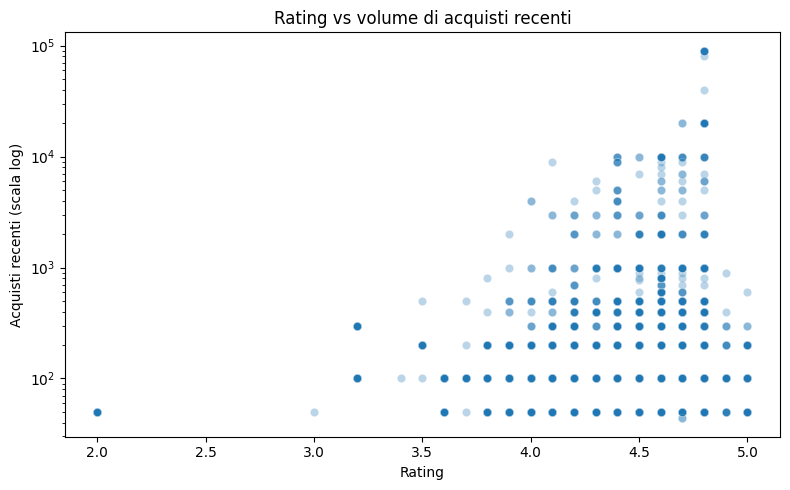

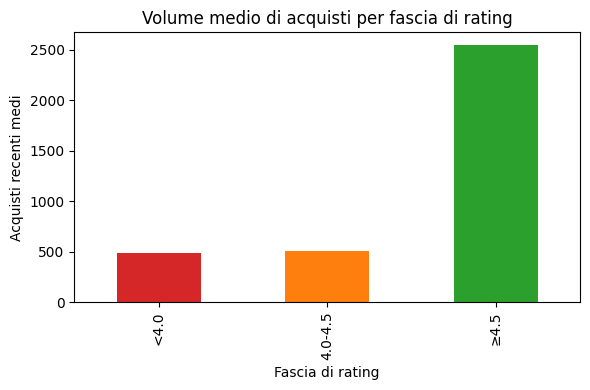


Top 10 per volume di acquisti recenti:
                                                                                                                                                                              Title  rating_num  reviews_num  bought_num
                                                                                                               Canon EF 24-70mm f/2.8L USM Standard Zoom Lens for Canon SLR Cameras         3.8        767.0   1315780.0
SAMSUNG Galaxy Tab S10 Ultra (14.6", Wi-Fi) SM-X920N, 256GB Storage + 12GB RAM, MediaTek Dimensity 9300+, AMOLED Display, Anti-Reflection, S Pen Included, AI Android Tablet (Gray)         4.1         26.0   1080000.0
                                                                                          Intel® Core™ i9 Desktop Processor 14900 24 Cores (8 P-cores and 16 E-cores) up to 5.8 GHz         4.9         21.0    828560.0
                                                                                            

In [24]:
df_clean = df.dropna(subset=['rating_num']).copy()
df_clean = df_clean[df_clean['bought_num'] > 0]

print("Record analizzati:", len(df_clean))
corr = df_clean['rating_num'].corr(df_clean['bought_num'])
print("Correlazione Pearson:", round(corr, 3))

df_clean['fascia'] = pd.cut(df_clean['rating_num'],
                            bins=[0, 4.0, 4.5, 5.1],
                            labels=['<4.0', '4.0-4.5', '≥4.5'])

print("\nVolume medio acquisti per fascia di rating:")
print(df_clean.groupby('fascia', observed=True)['bought_num'].mean().round(0))
print("Multiplo ≥4.5 rispetto a <4.0:", round(2544 / 488, 1), "x")

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_clean.sample(min(3000, len(df_clean))),
                x='rating_num', y='bought_num', alpha=0.3)
plt.yscale('log')
plt.title('Rating vs volume di acquisti recenti')
plt.xlabel('Rating')
plt.ylabel('Acquisti recenti (scala log)')
plt.tight_layout()
plt.show()
print("\n")
medie = df_clean.groupby('fascia', observed=True)['bought_num'].mean()
plt.figure(figsize=(6, 4))
medie.plot(kind='bar', color=['#d62728', '#ff7f0e', '#2ca02c'])
plt.title('Volume medio di acquisti per fascia di rating')
plt.ylabel('Acquisti recenti medi')
plt.xlabel('Fascia di rating')
plt.tight_layout()
plt.show()

print("\nTop 10 per volume di acquisti recenti:")
print(df_clean.nlargest(10, 'bought_num')[['Title', 'rating_num', 'reviews_num', 'bought_num']].to_string(index=False))

## Insight principale
I prodotti con rating più alto (soprattutto ≥ 4.5) mostrano in media più acquisti recenti.  
Le stelle funzionano come priming di fiducia: riducono il rischio percepito e aumentano la probabilità di acquisto nel breve periodo.

**Raccomandazione**: Prioritizzare visibilità e stock sui prodotti con rating ≥ 4.5 e volume di recensioni consistente. Monitorare quelli con molte recensioni ma rating basso.